# 6. Build an AI system around a model

**Goal:** separate retrieval, generation, deterministic tools, evaluation and serving. Build and call a small local API, then stop it cleanly. This notebook runs independently.

### Definitions

| Term | Definition |
|---|---|
| Retrieval | Find relevant information from a document collection |
| Chunk | A searchable piece of a document; our three short records are already chunks |
| Vector representation | Numeric representation used to compare items; here word-count vectors |
| Cosine similarity | Dot product divided by vector lengths; measures directional similarity |
| RAG | Retrieval-augmented generation: put retrieved context into a model's input before generation |
| Grounding | Connecting an answer's claims to supporting evidence |
| Tool call | Structured request to execute a specific allowed function |
| Serving | Expose application behavior through an interface such as HTTP |
| Latency | Elapsed time for a request |
| Observability | Measurements that help explain system behavior and failures |
| Abstention | Explicitly returning no answer when evidence is insufficient |
| Prompt injection | Untrusted text attempts to redirect a model's instructions |

This lesson uses fictional Sino Library records. Retrieval is a lexical word-count baseline, **not semantic embeddings**. The reliable API returns a hand-authored answer attached to a matched record, or a deterministic tool result. Separately, we try an actual tiny-model draft with retrieved context and show why retrieval alone does not make generation reliable. No production deployment or general question-answering capability is claimed.

In [1]:
from pathlib import Path
import sys

# Find the lesson folder from the notebook folder, mini_llm, or repository root.
candidates = [Path.cwd(), Path.cwd() / "learning_path",
              Path.cwd() / "mini_llm" / "learning_path"]
lesson_dir = next((p.resolve() for p in candidates if (p / "lab.py").is_file()), None)
if lesson_dir is None:
    raise FileNotFoundError("Open this notebook from learning_path, mini_llm, or the repository root.")
if str(lesson_dir) not in sys.path:
    sys.path.insert(0, str(lesson_dir))

import math
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import lab

torch.set_num_threads(2)
torch.manual_seed(42)
print("Local CPU lesson | PyTorch", torch.__version__)

Matplotlib is building the font cache; this may take a moment.


Local CPU lesson | PyTorch 2.14.1


### The application boundaries
The source attached to a lookup answer identifies the selected record. Attaching that record to a generated draft does **not** prove every generated claim is supported. Tool routing below is explicit JSON chosen by the caller; the tiny model does not autonomously choose tools.

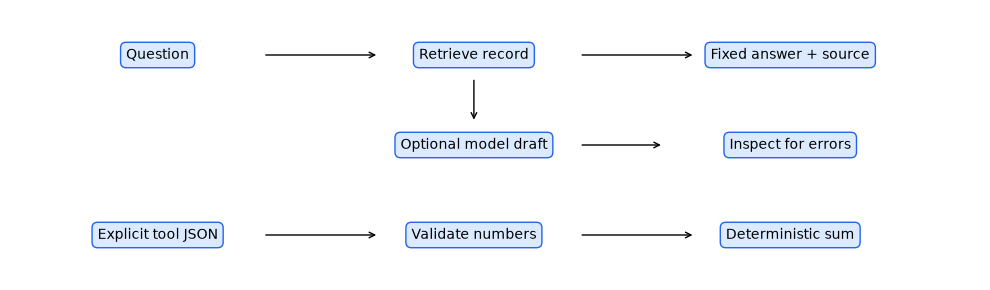

In [2]:
fig, ax = plt.subplots(figsize=(10, 3))
labels = [(0, 1, "Question"), (1.5, 1, "Retrieve record"), (3, 1, "Fixed answer + source"),
          (1.5, 0, "Optional model draft"), (3, 0, "Inspect for errors"),
          (0, -1, "Explicit tool JSON"), (1.5, -1, "Validate numbers"), (3, -1, "Deterministic sum")]
for x, y, text in labels:
    ax.text(x, y, text, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.4", fc="#dbeafe", ec="#2563eb"))
for y in (1, -1):
    for x in (0, 1.5): ax.annotate("", xy=(x+1.05, y), xytext=(x+0.5, y), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(1.5, 0.25), xytext=(1.5, 0.75), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(2.4, 0), xytext=(2.0, 0), arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-0.7, 3.9); ax.set_ylim(-1.5, 1.5); ax.axis("off")
plt.tight_layout(); plt.show()

### Step A — evaluate retrieval independently
Our queries deliberately share vocabulary with the documents. This measures a small known test set, not broad retrieval quality. No-match examples help check whether the system returns an answer for unrelated text.

**Recall@1** here is the fraction of relevant questions whose top result is the expected document. Unknown-query rejection is reported separately. The threshold is a teaching default, not a statistically calibrated confidence threshold.

In [3]:
retrieval_cases = [("opens closes weekdays", "hours"),
                   ("borrow books fourteen days", "borrowing"),
                   ("membership registration free", "membership")]
correct = 0
for question, expected in retrieval_cases:
    score, document = lab.retrieve(question)
    actual = document["id"] if document else None
    correct += actual == expected
    print(question, "->", actual, "score", round(score, 3))
print("Recall@1 on this tiny set:", correct / len(retrieval_cases))
assert correct == len(retrieval_cases)
assert lab.retrieve("volcano spacecraft")[1] is None
print("No-match response:", lab.answer_request({"question": "volcano spacecraft"}))

opens closes weekdays -> hours score 0.522
borrow books fourteen days -> borrowing score 0.632
membership registration free -> membership score 0.775
Recall@1 on this tiny set: 1.0
No-match response: {'mode': 'lookup', 'status': 'no_match', 'answer': None, 'source': None}


### Step B — try retrieval-augmented generation, then inspect the failure
We actually feed a retrieved fact into a locally trained model and generate a continuation. To fit its 48-character context, use a short compressed fact. This is a miniature RAG mechanics example; the base was trained only on simple sentences and is not instruction-tuned for answering questions.

The expected answer is `09:00`. Printing a generated string is not a successful quality test. A response that fails exact match is reported as such. Even an exact match on this one example would not establish general reliability.

In [4]:
model, _ = lab.make_demo_model(steps=60)
score, record = lab.retrieve("opens weekdays")
assert record is not None and record["id"] == "hours"
# Compress the known record only for this worked example, not a general summarizer.
context = "opens 09:00" if record["id"] == "hours" else record["text"]
prompt = f"Fact: {context}\nQ: opens?\nA: "
assert len(lab.encode(prompt)) < model.config.context_length
output = model.generate(prompt, max_new_tokens=30, greedy=True)
draft = output[len(prompt):]
print("Retrieved source:", record["id"])
print("Actual model input:", repr(prompt))
print("Unverified tiny-model draft:", repr(draft))
print("Exact-match answer check:", draft.strip() == "09:00")
print("Lookup baseline:", lab.answer_request({"question": "opens weekdays"}))

Retrieved source: hours
Actual model input: 'Fact: opens 09:00\nQ: opens?\nA: '
Unverified tiny-model draft: 'be blor bloooooooooks the the '
Exact-match answer check: False
Lookup baseline: {'mode': 'lookup', 'status': 'matched', 'answer': '09:00 to 18:00 on weekdays.', 'source': 'hours', 'score': 0.42640143271122083}


### Step C — use a tool for exact arithmetic
A tool receives structured data, validates it, then computes a result. This demo accepts only one explicit tool name, `sum`, and bounded finite numbers. It does not evaluate Python strings, access files, or run arbitrary commands.

In a real agent, model-proposed tool arguments are untrusted inputs. Tool permissions and validation must still apply. Retrieval documents are also untrusted data; do not let them authorize tool actions.

In [5]:
print(lab.answer_request({"tool": "sum", "numbers": [12, 8, 5]}))
for payload in [{"tool": "run_shell"}, {"tool": "sum", "numbers": [True]},
                {"tool": "sum", "numbers": [float("nan")]}]:
    try:
        lab.answer_request(payload)
    except ValueError as error:
        print("Rejected:", str(error))
    else:
        raise AssertionError("Unsafe/invalid tool input was accepted")

{'mode': 'tool', 'answer': 25}
Rejected: Unknown tool.
Rejected: Numbers must be finite and have magnitude at most one billion.
Rejected: Numbers must be finite and have magnitude at most one billion.


### Step D — serve the reliable baseline over local HTTP
`local_service.py` starts on `127.0.0.1` and an automatically chosen free port. The `with` block stops only the server it starts, even if a request fails. No service remains running after this cell.

We call the real HTTP endpoint, including invalid JSON and no-match cases. This API deliberately serves the lookup/tool baseline, not the unverified generated draft. Latency values are local single-request observations, not production percentiles. Bind errors under a restricted execution environment require permission to use local sockets.

In [6]:
import json
import time
import urllib.request
import urllib.error
from local_service import serve_local

def post(base_url, payload=None, raw=None):
    body = raw if raw is not None else json.dumps(payload).encode("utf-8")
    request = urllib.request.Request(base_url + "/ask", data=body,
                                     headers={"Content-Type": "application/json"})
    started = time.perf_counter()
    try:
        with urllib.request.urlopen(request, timeout=5) as response:
            return response.status, json.load(response), time.perf_counter()-started
    except urllib.error.HTTPError as error:
        return error.code, json.load(error), time.perf_counter()-started

with serve_local() as base_url:
    requests = [{"question": "membership registration free"},
                {"tool": "sum", "numbers": [12, 8, 5]},
                {"question": "volcano spacecraft"},
                {"question": ""}]
    results = [post(base_url, payload) for payload in requests]
    malformed = post(base_url, raw=b"not json")
    for status, body, elapsed in results + [malformed]:
        print(status, body, f"{elapsed*1000:.2f} ms")
    assert results[0][0] == 200 and results[0][1]["source"] == "membership"
    assert results[1][1]["answer"] == 25
    assert results[2][1]["status"] == "no_match"
    assert results[3][0] == 400 and malformed[0] == 400

# A request after the context must fail: the server is no longer listening.
try:
    post(base_url, {"question": "membership"})
except urllib.error.URLError:
    print("Passed: our local server has stopped.")
else:
    raise AssertionError("Server was still reachable after cleanup")

200 {'mode': 'lookup', 'status': 'matched', 'answer': 'Membership registration is free.', 'source': 'membership', 'score': 0.7745966692414834} 4.27 ms
200 {'mode': 'tool', 'answer': 25} 0.30 ms
200 {'mode': 'lookup', 'status': 'no_match', 'answer': None, 'source': None} 0.26 ms
400 {'error': 'Invalid request: check JSON, question or tool inputs.'} 0.27 ms
400 {'error': 'Invalid request: check JSON, question or tool inputs.'} 0.26 ms


Passed: our local server has stopped.


### Check your understanding

Retrieval found the right source, but the model generated a wrong opening time. Which part failed? Does a 200 HTTP response prove a good answer?

<details><summary>Suggested answer — try first</summary>

Retrieval succeeded on that example; generation or grounding failed. HTTP 200 means the request was handled under the API contract, not that the content is correct. Evaluate retrieval, answer correctness, source support, abstention and tools separately.

</details>

### Your exercises
1. Add a fourth fictional record and a paraphrased question. Does lexical retrieval still work?
2. Add a query that overlaps a record's words but asks an unsupported question. Observe that lexical overlap can produce an inappropriate matched answer. Propose an answerability check rather than claiming the score proves support.
3. Record a small table of answer correctness, retrieval correctness, tool success and latency. Keep actual user text out of logs unless needed and authorized.
4. Design how to replace the tiny draft model with a capable instruction model: preserve evidence, add output evaluation, protect tool permissions, and establish a cost/latency budget.

**Completion criterion:** make a real local request, reproduce a failure, identify which layer failed, and verify the server stops.

**Remaining work before production:** an appropriate generator if needed, broader evaluation, answerability and source-support checks, authentication/authorization as appropriate, concurrency and resource limits, monitoring, and deployment-specific review. The demo does not establish those properties.

Return to [README.md](README.md) and choose one exercise to implement yourself.